# Nombre:Emanuel Antonio Puentes Erazo 
# Codigo: A00410253

## Preparación y exploración de datos


Importamos las bibliotecas que necesitaremos para cargar, analizar y visualizar los datos, además de las herramientas de clasificación.

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid")
print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


Leemos el archivo CSV y revisamos sus dimensiones y primeras filas para validar la carga del conjunto de clientes.

In [48]:
df = pd.read_csv("clientes_domicilios_cali.csv")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (1500, 16)


,id_cliente,edad,zona,antiguedad_meses,plan_premium,metodo_pago,pedidos_mes,ticket_promedio,distancia_promedio_km,tiempo_entrega_promedio_min,uso_cupones_pct,quejas_6m,calificacion_app,dias_desde_ultimo_pedido,gasto_proximo_mes,abandono
0,CL00001,25.0,Sur,30,Si,Nequi,11,59200,4.6,25,3.7,0,4.4,0,736600,0
1,CL00002,21.0,Norte,3,No,Daviplata,2,30800,3.8,32,13.8,0,4.2,25,144800,0
2,CL00003,35.0,Oriente,6,No,Nequi,6,37300,6.6,41,45.6,1,4.3,18,252500,1
3,CL00004,32.0,Sur,27,No,Efectivo,10,39600,4.4,34,67.6,1,3.5,2,328200,0
4,CL00005,21.0,Sur,9,Si,Efectivo,7,28400,4.1,19,62.2,1,3.8,23,259400,0


Inspeccionamos las columnas, sus tipos de datos y el número de valores no nulos. Esto ayuda a detectar problemas de formato y campos incompletos.

In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_cliente                   1500 non-null   str    
 1   edad                         1456 non-null   float64
 2   zona                         1500 non-null   str    
 3   antiguedad_meses             1500 non-null   int64  
 4   plan_premium                 1500 non-null   str    
 5   metodo_pago                  1500 non-null   str    
 6   pedidos_mes                  1500 non-null   int64  
 7   ticket_promedio              1500 non-null   int64  
 8   distancia_promedio_km        1459 non-null   float64
 9   tiempo_entrega_promedio_min  1500 non-null   int64  
 10  uso_cupones_pct              1500 non-null   float64
 11  quejas_6m                    1500 non-null   int64  
 12  calificacion_app             1470 non-null   float64
 13  dias_desde_ultimo_pedido     

In [50]:
df.describe()

,edad,antiguedad_meses,pedidos_mes,ticket_promedio,distancia_promedio_km,tiempo_entrega_promedio_min,uso_cupones_pct,quejas_6m,calificacion_app,dias_desde_ultimo_pedido,gasto_proximo_mes,abandono
count,1456.000000,1500.000000,1500.000000,1500.000000,1459.000000,1500.000000,1500.000000,1500.000000,1470.000000,1500.000000,1.500000e+03,1500.000000
mean,30.548764,20.561333,7.877333,47905.933333,4.393763,30.382667,33.433533,1.075333,3.975170,14.273333,3.982783e+05,0.278667
std,8.766562,14.736769,7.885159,34866.915923,3.476179,8.216563,24.170144,1.431674,0.757842,17.873246,3.399163e+05,0.448493
min,18.000000,1.000000,0.000000,15700.000000,0.500000,5.000000,0.000000,0.000000,1.000000,0.000000,0.000000e+00,0.000000
25%,24.000000,6.000000,3.000000,33500.000000,2.800000,25.000000,13.475000,0.000000,3.600000,3.000000,1.699500e+05,0.000000
50%,29.000000,20.000000,6.000000,41750.000000,4.100000,30.000000,27.400000,1.000000,4.100000,8.000000,2.714000e+05,0.000000
75%,35.000000,32.000000,11.000000,55625.000000,5.400000,36.000000,53.225000,2.000000,4.500000,19.000000,4.910000e+05,1.000000
max,69.000000,72.000000,105.000000,574000.000000,59.600000,61.000000,100.000000,8.000000,5.000000,120.000000,1.910100e+06,1.000000


Contamos los valores faltantes de cada columna. Este diagnóstico orienta las decisiones de limpieza que se aplicarán más adelante.

In [92]:
df.isna().sum()

id_cliente                     0
edad                           0
antiguedad_meses               0
pedidos_mes                    0
ticket_promedio                0
distancia_promedio_km          0
tiempo_entrega_promedio_min    0
uso_cupones_pct                0
quejas_6m                      0
calificacion_app               0
dias_desde_ultimo_pedido       0
gasto_proximo_mes              0
abandono                       0
zona_Norte                     0
zona_Oeste                     0
zona_Oriente                   0
zona_Sur                       0
plan_premium_Si                0
metodo_pago_Efectivo           0
metodo_pago_Nequi              0
metodo_pago_Tarjeta            0
grupo                          0
dtype: int64

### Distribuciones de abandono y gasto
Graficamos cuántos clientes abandonan y observamos la distribución del gasto previsto.

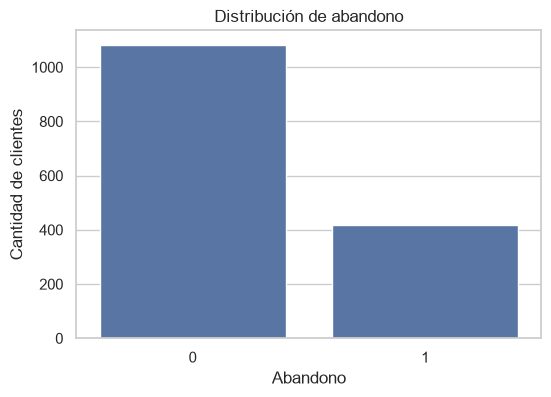

Porcentaje de abandono:
abandono
0    72.133333
1    27.866667
Name: proportion, dtype: float64


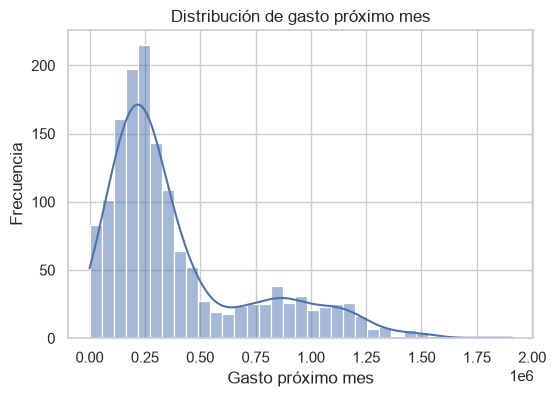

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribución de abandono
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="abandono")
plt.title("Distribución de abandono")
plt.xlabel("Abandono")
plt.ylabel("Cantidad de clientes")
plt.show()

print("Porcentaje de abandono:")
print(df["abandono"].value_counts(normalize=True) * 100)


# Distribución de gasto_proximo_mes
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="gasto_proximo_mes", kde=True)
plt.title("Distribución de gasto próximo mes")
plt.xlabel("Gasto próximo mes")
plt.ylabel("Frecuencia")
plt.show()

### Relaciones entre variables

Con un diagrama de caja comparamos el gasto del próximo mes entre clientes que abandonan y los que no. Así observamos diferencias en la mediana, dispersión y valores extremos.

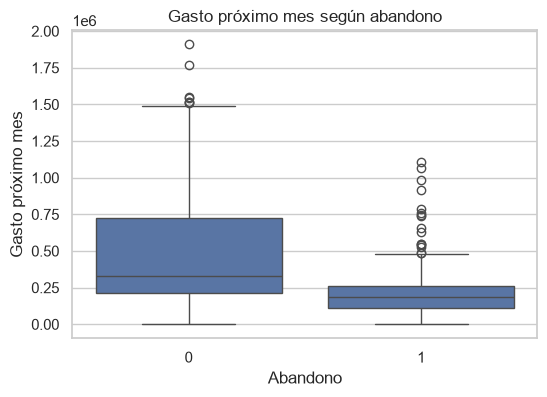

In [94]:
# 1. Abandono vs. gasto próximo mes (boxplot)
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="abandono", y="gasto_proximo_mes")
plt.title("Gasto próximo mes según abandono")
plt.xlabel("Abandono")
plt.ylabel("Gasto próximo mes")
plt.show()

Relacionamos los días transcurridos desde el último pedido con la cantidad de pedidos mensuales. 

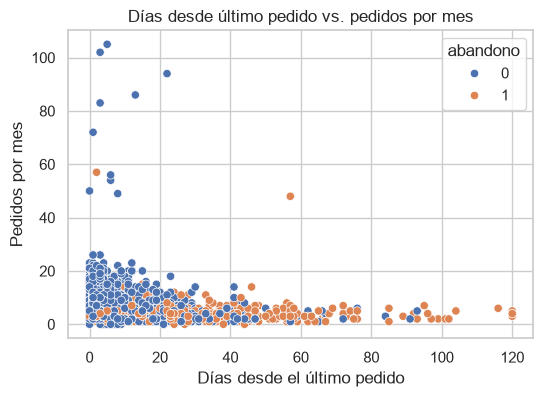

In [95]:
# 2. Días desde el último pedido vs. pedidos por mes (dispersión)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="dias_desde_ultimo_pedido", y="pedidos_mes", hue="abandono")
plt.title("Días desde último pedido vs. pedidos por mes")
plt.xlabel("Días desde el último pedido")
plt.ylabel("Pedidos por mes")
plt.show()

Graficamos la relación entre los pedidos mensuales y el gasto estimado, usando el abandono como categoría de color. 

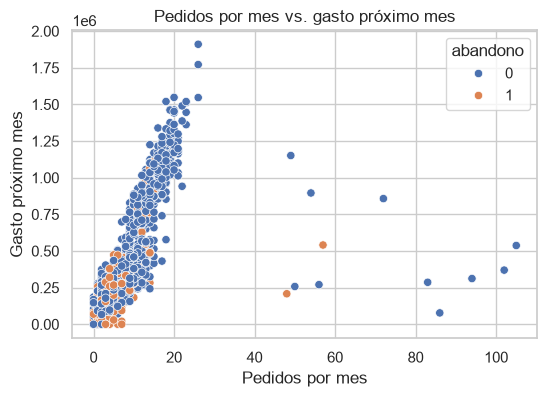

In [96]:
# 3. Pedidos por mes vs. gasto próximo mes (dispersión)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="pedidos_mes", y="gasto_proximo_mes", hue="abandono")
plt.title("Pedidos por mes vs. gasto próximo mes")
plt.xlabel("Pedidos por mes")
plt.ylabel("Gasto próximo mes")
plt.show()

### Tratamiento de valores faltantes
Imputamos con la mediana los datos faltantes de edad, distancia promedio y calificación de la aplicación. La mediana es menos sensible a valores extremos que el promedio.

In [52]:
mediana_edad = df["edad"].median()

df.loc[df["edad"].isna(), "edad"] = mediana_edad

print("Mediana de edad utilizada:", mediana_edad)


mediana_distancia = df["distancia_promedio_km"].median()

df.loc[df["distancia_promedio_km"].isna(), "distancia_promedio_km"] = mediana_distancia

print("Mediana de distancia promedio utilizada:", mediana_distancia)


mediana_calificacion = df["calificacion_app"].median()

df.loc[df["calificacion_app"].isna(), "calificacion_app"] = mediana_calificacion

print("Mediana de calificación utilizada:", mediana_calificacion)

Mediana de edad utilizada: 29.0
Mediana de distancia promedio utilizada: 4.1
Mediana de calificación utilizada: 4.1


Convertimos las categorías de zona, plan premium y método de pago en columnas indicadoras 

In [53]:
df = pd.get_dummies(df, columns=["zona", "plan_premium", "metodo_pago"], drop_first=True)

Separamos las variables predictoras de las variables objetivo: abandono para clasificación y gasto del próximo mes para regresión. En ambos casos se excluyen ambas columnas objetivo de las características.

In [54]:
# Modelo para predecir abandono
X_abandono = df.drop(columns=["abandono", "gasto_proximo_mes"])
y_abandono = df["abandono"]

# Modelo para predecir gasto_proximo_mes
X_gasto = df.drop(columns=["abandono", "gasto_proximo_mes"])
y_gasto = df["gasto_proximo_mes"]

## 1. Predicción de abandono
Empezamos por cuantificar cuántos clientes abandonan la aplicación y revisar su proporción. Esta es la variable objetivo del primer problema de clasificación.

Calculamos el conteo y el porcentaje de abandono para conocer la distribución 

In [55]:
conteo = df["abandono"].value_counts
print(conteo)
print()
print(f"Porcentaje de clientes que abandonan: {df['abandono'].mean()*100:.1f} %")

<bound method IndexOpsMixin.value_counts of 0       0
1       0
2       1
3       0
4       0
       ..
1495    1
1496    0
1497    1
1498    0
1499    0
Name: abandono, Length: 1500, dtype: int64>

Porcentaje de clientes que abandonan: 27.9 %


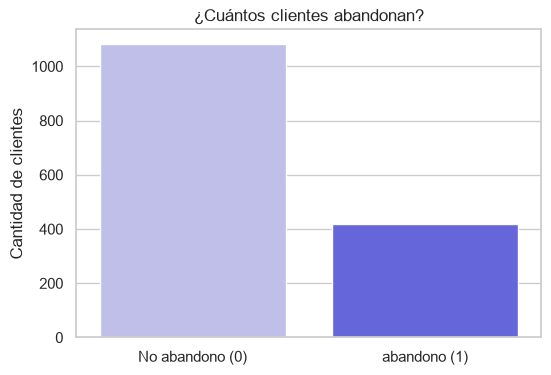

In [56]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="abandono", hue="abandono", palette=["#B8B8F0", "#5353EE"], legend=False)
plt.xticks([0, 1], ["No abandono (0)", "abandono (1)"])
plt.title("¿Cuántos clientes abandonan?")
plt.xlabel("")
plt.ylabel("Cantidad de clientes")
plt.show()

Comparamos los promedios de las variables numéricas según el abandono

In [57]:
numericas = ["edad", "antiguedad_meses", "pedidos_mes", "ticket_promedio", "distancia_promedio_km", "tiempo_entrega_promedio_min", "uso_cupones_pct", "quejas_6m", "calificacion_app", "dias_desde_ultimo_pedido", "gasto_proximo_mes"]
df.groupby("abandono")[numericas].mean().round(2)

,edad,antiguedad_meses,pedidos_mes,ticket_promedio,distancia_promedio_km,tiempo_entrega_promedio_min,uso_cupones_pct,quejas_6m,calificacion_app,dias_desde_ultimo_pedido,gasto_proximo_mes
abandono,,,,,,,,,,,
0,29.56,21.79,9.05,49696.86,4.32,29.98,34.40,0.74,4.19,9.60,474165.43
1,32.93,17.39,4.84,43270.10,4.55,31.42,30.94,1.93,3.42,26.37,201843.30


Mostramos la antigüedad según el abandono y calculamos la tasa de abandono para clientes con y sin quejas

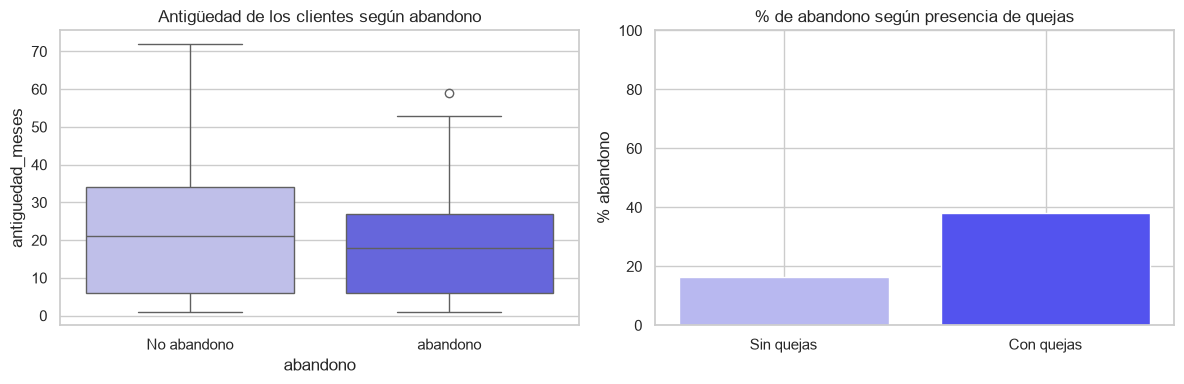

In [58]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="abandono", y="antiguedad_meses", hue="abandono", palette=["#B8B8F0", "#5353EE"], legend=False, ax=ejes[0])
ejes[0].set_title("Antigüedad de los clientes según abandono")
ejes[0].set_xticks([0, 1], ["No abandono", "abandono"])

tasa_abandono = df.groupby(df["quejas_6m"] > 0)["abandono"].mean() * 100
ejes[1].bar(["Sin quejas", "Con quejas"], tasa_abandono, color=["#B8B8F0", "#5353EE"])
ejes[1].set_title("% de abandono según presencia de quejas")
ejes[1].set_ylabel("% abandono")

ejes[1].set_ylim(0, 100)
plt.tight_layout()
plt.show()

Seleccionamos las variables numéricas para predecir el abandono y comprobamos las dimensiones de las características y de la etiqueta.

In [59]:
X = df[numericas]
y = df["abandono"]

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

Forma de X: (1500, 11)
Forma de y: (1500,)


### Árbol de decisión


Dividimos los datos en entrenamiento y prueba, manteniendo la proporción de abandono en ambos conjuntos

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Casos para entrenar:", len(X_train), "| % abandono:", round(y_train.mean()*100, 1))
print("Casos para probar:  ", len(X_test), " | % abandono:", round(y_test.mean()*100, 1))

Casos para entrenar: 1050 | % abandono: 27.9
Casos para probar:   450  | % abandono: 27.8


In [61]:
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_train, y_train)

print("✅ ¡Árbol entrenado!")

✅ ¡Árbol entrenado!


Dibujamos el árbol entrenado para visualizar las reglas de decisión 

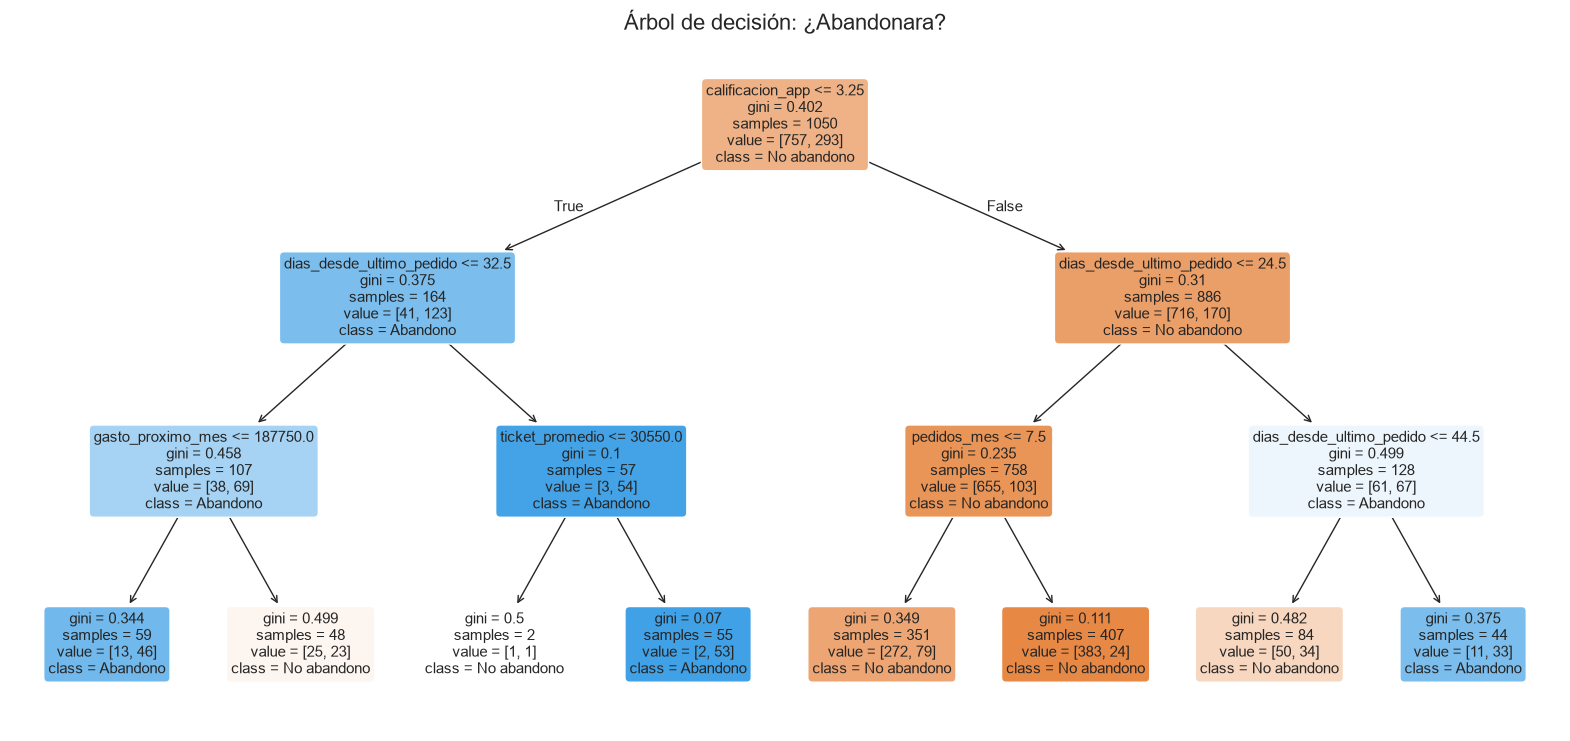

In [62]:
plt.figure(figsize=(20, 9))
plot_tree(arbol, feature_names=numericas, class_names=["No abandono", "Abandono"],
          filled=True, rounded=True, fontsize=11)
plt.title("Árbol de decisión: ¿Abandonara?", fontsize=16)
plt.show()

Cuáles características contribuyeron más a sus decisiones

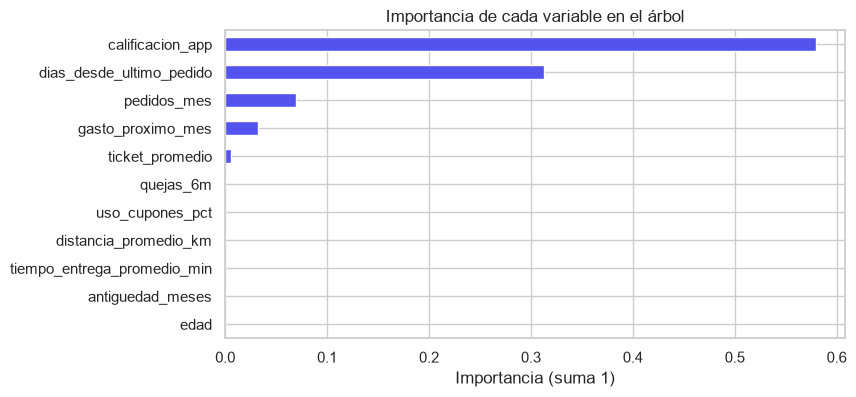

In [63]:
importancia = pd.Series(arbol.feature_importances_, index=numericas).sort_values()

plt.figure(figsize=(8, 4))
importancia.plot(kind="barh", color="#5353EE")
plt.title("Importancia de cada variable en el árbol")
plt.xlabel("Importancia (suma 1)")
plt.show()

Predecimos el abandono para el conjunto de prueba y calculamos el accuracy

In [64]:
y_pred_arbol = arbol.predict(X_test)

print(f"Accuracy del árbol: {accuracy_score(y_test, y_pred_arbol)*100:.1f} %")

Accuracy del árbol: 77.1 %


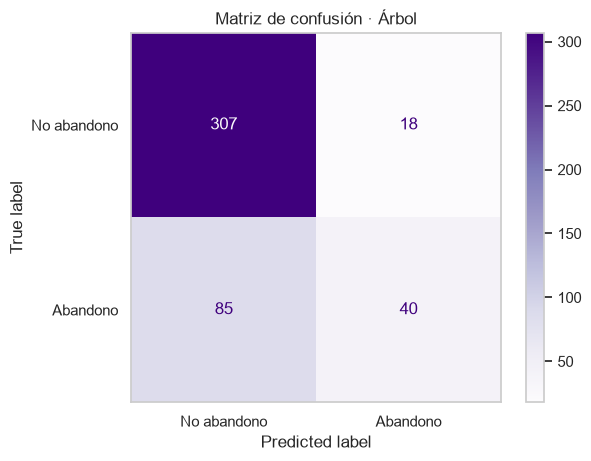

In [65]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_arbol, display_labels=["No abandono", "Abandono"], cmap="Purples"
)
plt.title("Matriz de confusión · Árbol")
plt.grid(False)
plt.show()

Consultamos precision, recall y F1-score por clase

In [66]:
print(classification_report(y_test, y_pred_arbol, target_names=["No abandono", "Abandono"]))

              precision    recall  f1-score   support

 No abandono       0.78      0.94      0.86       325
    Abandono       0.69      0.32      0.44       125

    accuracy                           0.77       450
   macro avg       0.74      0.63      0.65       450
weighted avg       0.76      0.77      0.74       450



### Regresión logística


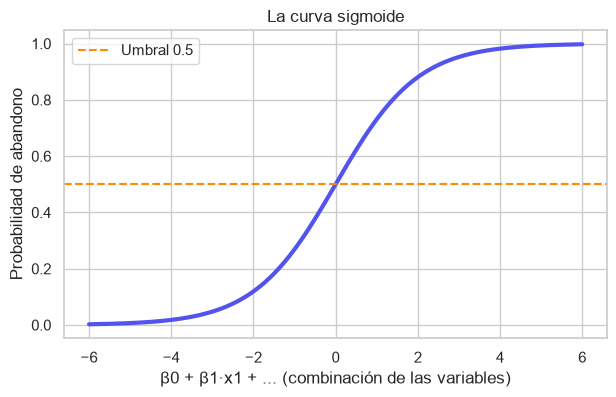

In [67]:
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(7, 4))
plt.plot(z, 1 / (1 + np.exp(-z)), color="#5353EE", linewidth=3)
plt.axhline(0.5, color="#FF8A00", linestyle="--", label="Umbral 0.5")
plt.title("La curva sigmoide")
plt.xlabel("β0 + β1·x1 + ... (combinación de las variables)")
plt.ylabel("Probabilidad de abandono")
plt.legend()
plt.show()

In [68]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logistica = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)
logistica.fit(X_train, y_train)
y_pred_log = logistica.predict(X_test)

print("✅ ¡Regresión logística entrenada!")
print(f"Accuracy de la regresión logística: {accuracy_score(y_test, y_pred_log)*100:.1f} %")

✅ ¡Regresión logística entrenada!
Accuracy de la regresión logística: 72.9 %


Visualizamos la matriz de confusión de la regresión logística para analizar en qué clases se concentran sus aciertos y equivocaciones

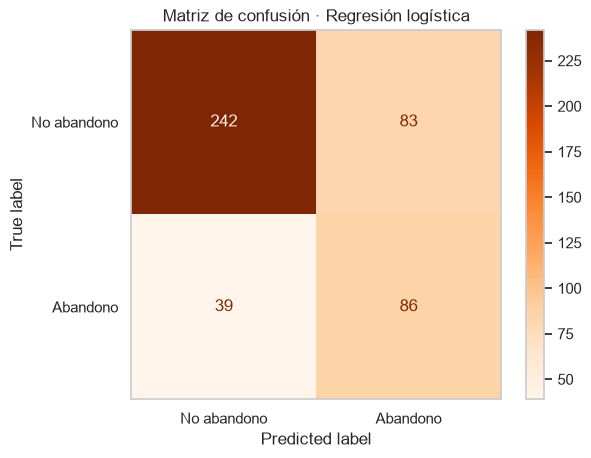

In [69]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_log,
    labels=[0, 1],
    display_labels=["No abandono", "Abandono"],
    cmap="Oranges"
)
plt.title("Matriz de confusión · Regresión logística")
plt.grid(False)
plt.show()

### Comparación de clasificadores
Comparamos árbol y regresión logística usando accuracy, precision y recall en el mismo conjunto de prueba. Estas métricas permiten valorar los modelos desde distintos enfoques.

In [70]:
comparacion = pd.DataFrame({
    "Modelo": ["Árbol de decisión", "Regresión logística"],
    "Accuracy": [accuracy_score(y_test, y_pred_arbol), accuracy_score(y_test, y_pred_log)],
    "Precision": [precision_score(y_test, y_pred_arbol), precision_score(y_test, y_pred_log)],
    "Recall": [recall_score(y_test, y_pred_arbol), recall_score(y_test, y_pred_log)],
}).round(3)
comparacion

,Modelo,Accuracy,Precision,Recall
0,Árbol de decisión,0.771,0.690,0.320
1,Regresión logística,0.729,0.509,0.688


### Predicción para clientes nuevos
Creamos dos ejemplos ficticios con características conocidas y aplicamos ambos modelos para estimar su abandono y la probabilidad asociada.

In [71]:
nuevos = pd.DataFrame({
    "edad": [25, 35],
    "antiguedad_meses": [12, 24],
    "pedidos_mes": [5, 10],
    "ticket_promedio": [50, 100],
    "distancia_promedio_km": [10, 20],
    "tiempo_entrega_promedio_min": [30, 60],
    "uso_cupones_pct": [20, 40],
    "quejas_6m": [1, 3],
    "calificacion_app": [4, 5],
    "dias_desde_ultimo_pedido": [7, 14],
    "gasto_proximo_mes": [250, 500]
}, index=["Cliente A", "Cliente B"])

columnas_modelo = list(arbol.feature_names_in_)
X_nuevos = nuevos[columnas_modelo]
nuevos["prediccion_arbol"] = np.where(
    arbol.predict(X_nuevos) == 1, "Abandono", "No abandono"
)
nuevos["prob_abandono_logistica"] = (
    logistica.predict_proba(X_nuevos)[:, 1] * 100
).round(1)

nuevos

,edad,antiguedad_meses,pedidos_mes,ticket_promedio,distancia_promedio_km,tiempo_entrega_promedio_min,uso_cupones_pct,quejas_6m,calificacion_app,dias_desde_ultimo_pedido,gasto_proximo_mes,prediccion_arbol,prob_abandono_logistica
Cliente A,25,12,5,50,10,30,20,1,4,7,250,No abandono,42.1
Cliente B,35,24,10,100,20,60,40,3,5,14,500,No abandono,60.1


## 2. Predicción del gasto del próximo mes
En esta parte estimamos el gasto mensual de cada cliente mediante regresión lineal, usando el número de pedidos como variable predictora.

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


In [73]:
numericas = df.select_dtypes(include="number")
correlaciones = numericas.corr()["gasto_proximo_mes"].drop("gasto_proximo_mes").sort_values(ascending=False)
correlaciones.round(2)

pedidos_mes                    0.59
antiguedad_meses               0.58
calificacion_app               0.46
ticket_promedio                0.33
edad                           0.12
distancia_promedio_km         -0.02
tiempo_entrega_promedio_min   -0.07
quejas_6m                     -0.33
uso_cupones_pct               -0.35
abandono                      -0.36
dias_desde_ultimo_pedido      -0.40
Name: gasto_proximo_mes, dtype: float64

Representamos las correlaciones entre las variables numéricas con un mapa de calor para identificar relaciones positivas y negativas.

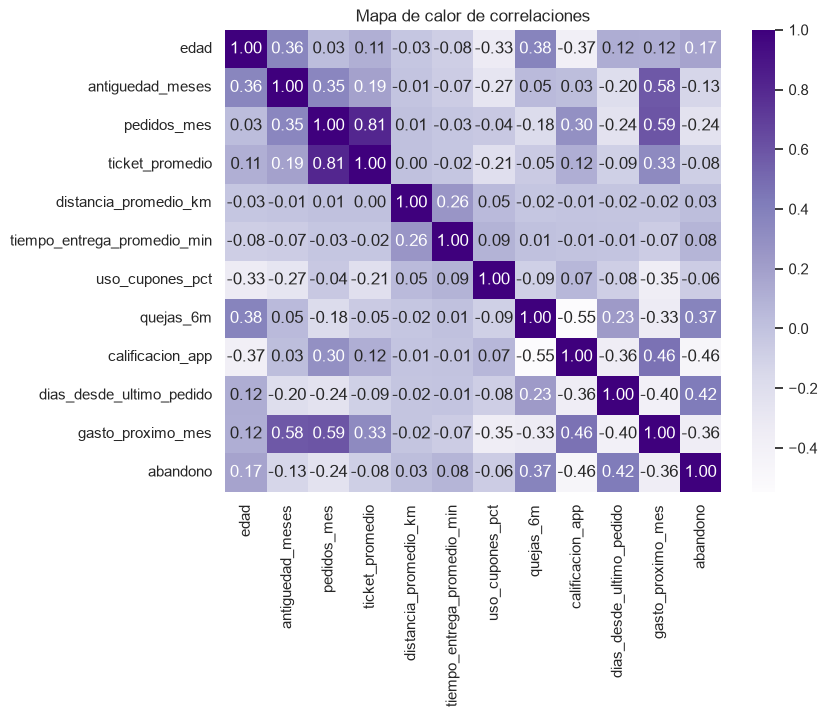

In [74]:
plt.figure(figsize=(8, 6))
sns.heatmap(numericas.corr(), annot=True, fmt=".2f", cmap="Purples")
plt.title("Mapa de calor de correlaciones")
plt.show()

Graficamos los pedidos mensuales frente al gasto esperado para observar visualmente la tendencia que usará la regresión lineal.

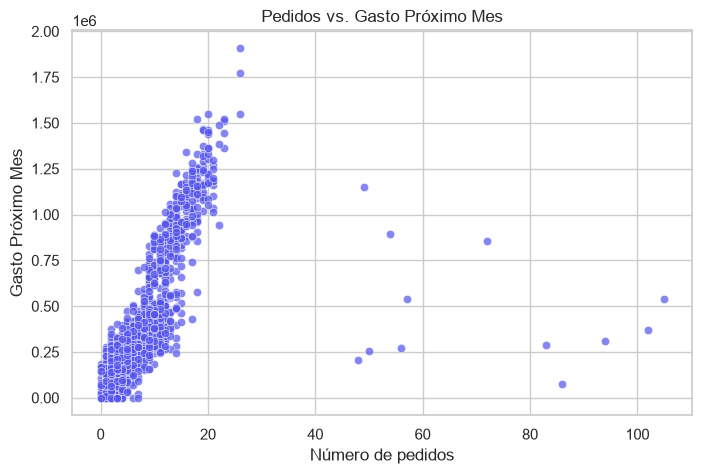

In [75]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="pedidos_mes", y="gasto_proximo_mes", color="#5353EE", alpha=0.7)
plt.title("Pedidos vs. Gasto Próximo Mes")
plt.xlabel("Número de pedidos")
plt.ylabel("Gasto Próximo Mes")
plt.show()

In [76]:
X = df[["pedidos_mes"]]
y = df["gasto_proximo_mes"]

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

Forma de X: (1500, 1)
Forma de y: (1500,)


Separamos los registros en entrenamiento y prueba para ajustar la regresión 

In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Casos para entrenar:", len(X_train))
print("Casos para probar:  ", len(X_test))

Casos para entrenar: 1200
Casos para probar:   300


In [78]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

print("✅ ¡Modelo entrenado!")

✅ ¡Modelo entrenado!


In [79]:
b0 = modelo.intercept_
b1 = modelo.coef_[0]

print(f"Intercepto (β0): {b0:.3f}")
print(f"Pendiente  (β1): {b1:.3f}")
print()
print(f"Ecuación: gasto_proximo_mes = {b0:.2f} + {b1:.3f} × pedidos_mes")
print()
print(f"👉 Por cada pedido adicional, el gasto próximo mes aumenta en promedio {b1:,.0f}.")

Intercepto (β0): 171087.718
Pendiente  (β1): 28449.261

Ecuación: gasto_proximo_mes = 171087.72 + 28449.261 × pedidos_mes

👉 Por cada pedido adicional, el gasto próximo mes aumenta en promedio 28,449.


Trazamos la recta de regresión junto con los datos de entrenamiento y prueba para observar visualmente cómo se ajusta el modelo.

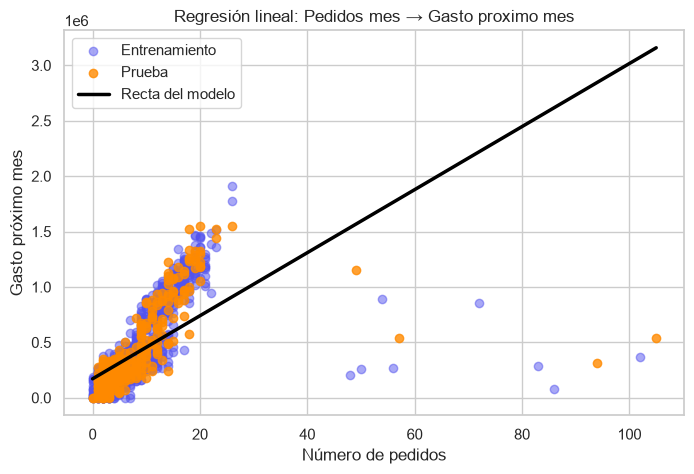

In [80]:
x_linea = pd.DataFrame({"pedidos_mes": np.linspace(df["pedidos_mes"].min(), df["pedidos_mes"].max(), 100)})
y_linea = modelo.predict(x_linea)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color="#5353EE", alpha=0.5, label="Entrenamiento")
plt.scatter(X_test, y_test, color="#FF8A00", alpha=0.8, label="Prueba")
plt.plot(x_linea, y_linea, color="black", linewidth=2.5, label="Recta del modelo")
plt.title("Regresión lineal: Pedidos mes → Gasto proximo mes")
plt.xlabel("Número de pedidos")
plt.ylabel("Gasto próximo mes")
plt.legend()
plt.show()

Evaluamos las predicciones del conjunto de prueba con MAE, RMSE y R² para resumir la magnitud del error y la capacidad explicativa del modelo.

In [81]:
y_pred = modelo.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print(f"MAE : {mae:.2f} gasto proximo mes")
print(f"RMSE: {rmse:.2f} gasto proximo mes")
print(f"R²  : {r2:.3f}  →  el modelo explica el {r2*100:.1f} % de la variación") 


MAE : 195805.35 gasto proximo mes
RMSE: 325631.67 gasto proximo mes
R²  : 0.213  →  el modelo explica el 21.3 % de la variación


Generamos predicciones para el conjunto de prueba y calculamos MAE, RMSE y R². Estas métricas resumen el tamaño de los errores y la variación explicada.

In [82]:
comparacion = pd.DataFrame({
    "pedidos_mes": X_test["pedidos_mes"].values,
    "gasto_proximo_mes": y_test.values,
    "gasto_predicho": y_pred.round(2),
})
comparacion["error"] = (comparacion["gasto_proximo_mes"] - comparacion["gasto_predicho"]).round(2)
comparacion.head(10)

,pedidos_mes,gasto_proximo_mes,gasto_predicho,error
0,105,537400,3158260.15,-2620860.15
1,5,153000,313334.02,-160334.02
2,3,167600,256435.50,-88835.50
3,4,249400,284884.76,-35484.76
4,12,621100,512478.85,108621.15
5,1,162700,199536.98,-36836.98
6,3,90700,256435.50,-165735.50
7,5,344800,313334.02,31465.98
8,20,1222500,740072.94,482427.06
9,2,60100,227986.24,-167886.24


Contrastamos los valores reales con los predichos. La diagonal representa predicciones perfectas; cuanto más cerca estén los puntos, menor es el error visual.

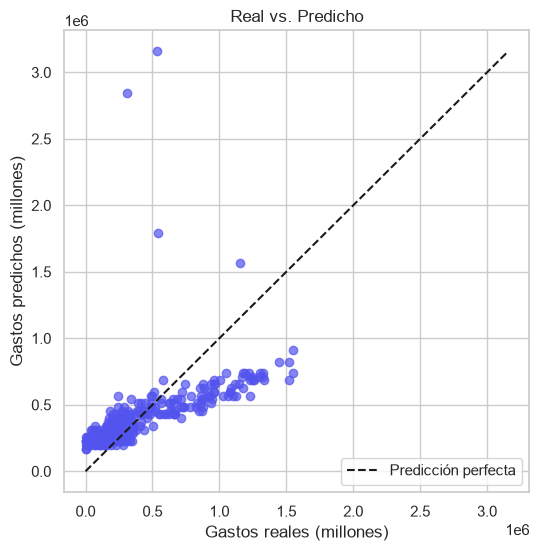

In [83]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, color="#5353EE", alpha=0.7)
limites = [0, max(y_test.max(), y_pred.max()) + 2]
plt.plot(limites, limites, "k--", label="Predicción perfecta")
plt.xlabel("Gastos reales (millones)")
plt.ylabel("Gastos predichos (millones)")
plt.title("Real vs. Predicho")
plt.legend()
plt.show()

Usamos el modelo entrenado para estimar el gasto de nuevos casos con diferentes cantidades de pedidos y mostramos los resultados en una tabla.

In [84]:
nuevas = pd.DataFrame({"pedidos_mes": [20, 80, 150, 300]})
nuevas["gasto_proximo_mes"] = modelo.predict(nuevas).round(2)
nuevas

,pedidos_mes,gasto_proximo_mes
0,20,740072.94
1,80,2447028.62
2,150,4438476.90
3,300,8705866.09


## Bonus: detección de anomalías y segmentación

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


### Detección de anomalías
Combinamos dos enfoques: la regla del rango intercuartílico (IQR) en variables seleccionadas y Isolation Forest. Después contamos las observaciones que cada método identifica como atípicas.

In [99]:
from sklearn.ensemble import IsolationForest

variables_anomalias = ["pedidos_mes", "ticket_promedio", "distancia_promedio_km"]

# 1. Regla 1,5 * IQR
for variable in variables_anomalias:
    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)
    IQR = Q3 - Q1

    df[variable + "_IQR"] = (
        (df[variable] < Q1 - 1.5 * IQR) |
        (df[variable] > Q3 + 1.5 * IQR)
    )

df["anomalia_IQR"] = df[
    [v + "_IQR" for v in variables_anomalias]
].any(axis=1)

# 2. Isolation Forest
X_anom = df[variables_anomalias].copy()
X_anom = X_anom.fillna(X_anom.median())

modelo = IsolationForest(contamination=0.02, random_state=42)
df["anomalia_IF"] = modelo.fit_predict(X_anom) == -1

# 3. Comparar resultados
print("Anomalías por IQR:", df["anomalia_IQR"].sum())
print("Anomalías por Isolation Forest:", df["anomalia_IF"].sum())
print("Detectadas por ambos métodos:",
      (df["anomalia_IQR"] & df["anomalia_IF"]).sum())

# 4. Mostrar 3 casos sospechosos
sospechosos = df[df["anomalia_IQR"] | df["anomalia_IF"]]


Anomalías por IQR: 32
Anomalías por Isolation Forest: 30
Detectadas por ambos métodos: 22


### Preparación para clustering


In [87]:
variables = ["pedidos_mes", "ticket_promedio", "uso_cupones_pct",
             "calificacion_app", "quejas_6m", "dias_desde_ultimo_pedido", "antiguedad_meses"]
X = df[variables]

escalador = StandardScaler()
X_esc = escalador.fit_transform(X)

print("Antes de escalar (desviación estándar):")
print(X.std().round(1))
print()
print("Después de escalar (desviación estándar):")
print(pd.DataFrame(X_esc, columns=variables).std().round(1))

Antes de escalar (desviación estándar):
pedidos_mes                     7.9
ticket_promedio             34866.9
uso_cupones_pct                24.2
calificacion_app                0.8
quejas_6m                       1.4
dias_desde_ultimo_pedido       17.9
antiguedad_meses               14.7
dtype: float64

Después de escalar (desviación estándar):
pedidos_mes                 1.0
ticket_promedio             1.0
uso_cupones_pct             1.0
calificacion_app            1.0
quejas_6m                   1.0
dias_desde_ultimo_pedido    1.0
antiguedad_meses            1.0
dtype: float64


Grafica del metodo del codo

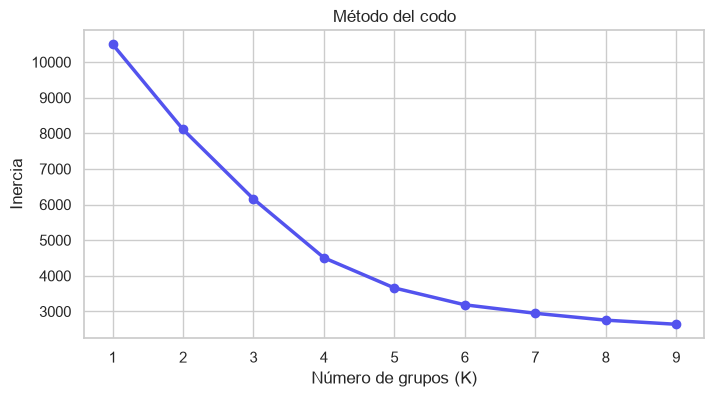

In [88]:
ks = range(1, 10)
inercias = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_esc)
    inercias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(ks, inercias, marker="o", color="#5353EE", linewidth=2.5)
plt.title("Método del codo")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Inercia")
plt.xticks(list(ks))
plt.show()

### Ajuste de K-means
Usamos seis grupos, según la elección realizada a partir del método del codo. 

In [89]:
kmeans = KMeans(n_clusters= 6, n_init=10, random_state=42)
df["grupo"] = kmeans.fit_predict(X_esc)

print("✅ ¡Clustering listo!")
print()
print("Jugadores por grupo:")
print(df["grupo"].value_counts().sort_index())

✅ ¡Clustering listo!

Jugadores por grupo:
grupo
0    249
1    416
2    347
3    405
4     71
5     12
Name: count, dtype: int64


### Perfil de los grupos
Calculamos el promedio de las variables seleccionadas para cada grupo y añadimos su tamaño.

In [90]:
perfil = df.groupby("grupo")[variables].mean().round(1)
perfil["cantidad"] = df["grupo"].value_counts().sort_index()
perfil

,pedidos_mes,ticket_promedio,uso_cupones_pct,calificacion_app,quejas_6m,dias_desde_ultimo_pedido,antiguedad_meses,cantidad
grupo,,,,,,,,
0,3.9,45373.5,18.8,2.8,3.3,20.5,24.8,249
1,8.1,31712.7,65.5,4.1,0.9,8.6,20.5,416
2,14.3,67687.9,9.7,4.6,0.3,3.9,37.3,347
3,3.5,40038.5,30.4,4.2,0.5,15.3,4.9,405
4,3.6,43085.9,25.1,3.4,1.4,71.4,14.1,71
5,71.3,383833.3,65.3,4.3,1.0,10.5,16.3,12


### Etiquetas para los grupos
Asociamos una etiqueta legible a cada número de grupo y resumimos nuevamente sus características para facilitar la interpretación

In [101]:
nombres = {
    0: "Insatisfechos",
    1: "Frecuentes a promociones",
    2: "De alto valor y leales",
    3: "Nuevos satisfechos",
    4: "Inactivos",
    5: "Consumo execepcionales",
}

df["tipo_cliente"] = df["grupo"].map(nombres)

df.groupby("tipo_cliente")[variables].mean().round(1)

,pedidos_mes,ticket_promedio,uso_cupones_pct,calificacion_app,quejas_6m,dias_desde_ultimo_pedido,antiguedad_meses
tipo_cliente,,,,,,,
Consumo execepcionales,71.3,383833.3,65.3,4.3,1.0,10.5,16.3
De alto valor y leales,14.3,67687.9,9.7,4.6,0.3,3.9,37.3
Frecuentes a promociones,8.1,31712.7,65.5,4.1,0.9,8.6,20.5
Inactivos,3.6,43085.9,25.1,3.4,1.4,71.4,14.1
Insatisfechos,3.9,45373.5,18.8,2.8,3.3,20.5,24.8
Nuevos satisfechos,3.5,40038.5,30.4,4.2,0.5,15.3,4.9


## Conclusiones y recomendaciones para DomiCali

Para DomiCali recomiendo utilizar diferentes modelos según la pregunta que se quiera resolver. Para predecir el abandono de clientes, recomiendo la regresión logística, porque permite estimar qué clientes tienen mayor probabilidad de irse y ayuda a saber cuáles necesitan más atención. Su confiabilidad se recomienda comprobar con los resultados de las pruebas del modelo, ya que una predicción no garantiza que un cliente vaya a abandonar

Para estimar el gasto del próximo mes, recomiendo un modelo de regresión, porque permite calcular cuánto podría gastar cada cliente según sus características y comportamiento de compra. Esto puede ayudar a planear las ventas, aunque pueden presentar errores si cambian los hábitos de los clientes

Para conocer los perfiles de clientes, recomiendo el agrupamiento K-Means, que permite organizar a los clientes en seis grupos con comportamientos similares. Esto facilita identificar diferentes clientes que deben definirse según los resultados obtenidos.

Finalmente, para detectar anomalías, recomiendo combinar la regla del 1,5·IQR con Isolation Forest. Estos métodos permiten encontrar clientes con comportamientos inusuales en variables como pedidos por mes, ticket promedio y distancia promedio. Cabe aclarar que un dato inusual no necesariamente es un error o un comportamiento negativo or eso, los casos identificados deben revisarse antes de tomar alguna decision

Como acción concreta, sugiero que DomiCali empiece por contactar a los clientes con mayor riesgo de abandono, ofreciéndoles promociones o beneficios. También puede diseñar campañas según los perfiles encontrados y revisar los casos sospechosos para identificar errores o situaciones que necesiten atención.

## Declaración del uso de inteligencia artificial

Utilicé inteligencia artificial como apoyo para comentar y comprender partes del código, corregir algunos aspectos de la aplicación de la regla del 1,5·IQR y proponer nombres para los perfiles de clientes identificados mediante agrupamiento. 